# Langkah 7 Anggota A — Split Data per Aktor dan Partisi Uji Stabilitas

**Tujuan:**
1. Membuat **split utama** (`splits.json`): aktor 1–16 train, 17–20 validation, 21–24 test. Split ini dipakai B untuk baseline dan SA, dan dipakai C untuk evaluasi akhir.
2. Membuat **5 partisi speaker** (`partitions.json`) untuk failure experiment: apakah fitur yang dipilih SA tetap sama jika aktor train/test diganti?
3. **Memeriksa 5 file tanpa frame bersuara** yang ditemukan di langkah 5.

**Kenapa dibagi per aktor, bukan per file?** Jika rekaman aktor yang sama ada di train dan test, model bisa "menghafal" suara orangnya, bukan emosinya, sehingga skor terlihat tinggi palsu. Dengan split per aktor, test selalu berisi orang yang belum pernah didengar model (*speaker-independent*).

**Rancangan partisi (siklik)**

Aktor dibagi ke 5 kelompok berisi 4 orang (2 laki-laki, 2 perempuan):

| Kelompok | Aktor | Cara ditentukan |
| --- | --- | --- |
| G0 | 21, 22, 23, 24 | Test split utama |
| G1 | 17, 18, 19, 20 | Validation split utama |
| G2, G3, G4 | 12 aktor dari 1–16 | Diundi dengan seed 42 (6 L, 6 P) |
| (selalu train) | 4 aktor sisanya dari 1–16 | Tidak pernah jadi test atau validation |

Partisi `Pk` memakai **test = Gk**, **validation = G(k+1)** (berputar, G4 → G0), dan **train = sisanya (16 aktor)**. Hasilnya:
- **P0 sama persis dengan split utama**, jadi run SA utama bisa langsung dipakai sebagai salah satu partisi.
- Setiap aktor paling banyak sekali menjadi test dan sekali menjadi validation.
- Semua partisi berukuran sama (16/4/4 aktor) dan seimbang gender.

**Input dan output**

| Jenis | Lokasi (di `MyDrive/project07/`) | Keterangan |
| --- | --- | --- |
| Input | `data/features/features_none.csv` | Dari langkah 5 (untuk menghitung jumlah file per split dan `voiced_ratio`) |
| Input | `data/metadata.csv`, `data/preprocess_log.csv` | Dari langkah 1 dan 4 |
| Input | `data/processed/ravdess_16k_trim/` | Audio 5 file yang diperiksa |
| Output | `data/splits.json` | Split utama (daftar aktor) |
| Output | `data/partitions.json` | 5 partisi P0–P4 (daftar aktor) |
| Output | `src/data_splits.py` | Fungsi pembaca split untuk B dan C |
| Output | `config.json` | Bagian `splits` (seed, versi, config_hash) |
| Output | `data/unvoiced_check.csv` | Hasil pemeriksaan 5 file tanpa frame bersuara |
| Output | `figures/splits/` | 2 grafik + `splits_summary.txt` |
| Output | `docs/README_langkah7_split_partisi.md` | Dokumentasi standar langkah ini |

**Prasyarat:** langkah 5 selesai. **Perkiraan waktu:** 2–5 menit.

**Cara pakai:** jalankan sel berurutan dengan `Shift + Enter`.

## Sel 1 — Persiapan dan cek prasyarat

Sel ini berdiri sendiri, jadi aman dijalankan di sesi Colab baru.

In [1]:
import os
import sys
import json
import hashlib
import importlib
from datetime import datetime

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import Audio, display

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/project07'
except ImportError:
    BASE_DIR = os.path.abspath('project07')

DATA_DIR = os.path.join(BASE_DIR, 'data')
PROC_DIR = os.path.join(DATA_DIR, 'processed', 'ravdess_16k_trim')
FEAT_DIR = os.path.join(DATA_DIR, 'features')
SRC_DIR = os.path.join(BASE_DIR, 'src')
FIG_DIR = os.path.join(BASE_DIR, 'figures', 'splits')
DOC_DIR = os.path.join(BASE_DIR, 'docs')
CONFIG_PATH = os.path.join(BASE_DIR, 'config.json')
MODULE_PATH = os.path.join(SRC_DIR, 'data_splits.py')
for d in [SRC_DIR, FIG_DIR, DOC_DIR]:
    os.makedirs(d, exist_ok=True)

wajib = [os.path.join(FEAT_DIR, 'features_none.csv'),
         os.path.join(FEAT_DIR, 'feature_names.csv'),
         os.path.join(DATA_DIR, 'metadata.csv'),
         os.path.join(DATA_DIR, 'preprocess_log.csv'),
         CONFIG_PATH]
hilang = [p for p in wajib if not os.path.exists(p)]
if hilang:
    raise FileNotFoundError('File prasyarat tidak ditemukan (jalankan langkah 5 dulu):\n' + '\n'.join(hilang))

fn = pd.read_csv(os.path.join(FEAT_DIR, 'features_none.csv'))
meta = pd.read_csv(os.path.join(DATA_DIR, 'metadata.csv'))
plog = pd.read_csv(os.path.join(DATA_DIR, 'preprocess_log.csv'))
with open(CONFIG_PATH, encoding='utf-8') as f:
    CONFIG = json.load(f)
if 'features' not in CONFIG:
    raise KeyError('config.json belum punya bagian "features". Jalankan langkah 5 dulu.')

ACTORS = sorted(fn['actor'].unique().tolist())
GENDER = fn.groupby('actor')['gender'].first().to_dict()
EMOTIONS = ['neutral', 'calm', 'happy', 'sad', 'angry', 'fearful', 'disgust', 'surprised']

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e',
                     'axes.titlecolor': '#0b0b0b', 'font.size': 10})

print('BASE_DIR      :', BASE_DIR)
print('File fitur    :', len(fn), 'baris')
print('Aktor         :', len(ACTORS), '->', ACTORS[:3], '...', ACTORS[-3:])
print('config_hash fitur:', CONFIG['features']['config_hash'])
if len(ACTORS) != 24 or len(fn) != 1440:
    print('[CEK] Jumlah aktor/file tidak sesuai harapan (24 aktor, 1440 file).')

Mounted at /content/drive
BASE_DIR      : /content/drive/MyDrive/project07
File fitur    : 1440 baris
Aktor         : 24 -> [1, 2, 3] ... [22, 23, 24]
config_hash fitur: 0c3114fc78


## Sel 2 — Buat split utama dan 5 partisi

Seed 42 dipakai untuk mengundi kelompok G2–G4 dari aktor 1–16, sehingga hasilnya selalu sama setiap kali dijalankan. Sel ini menulis `data/splits.json`, `data/partitions.json`, dan bagian `splits` di `config.json`.

In [2]:
SEED = 42
MAIN = {'train': list(range(1, 17)), 'validation': [17, 18, 19, 20], 'test': [21, 22, 23, 24]}

# Kelompok G0..G4 (masing-masing 2 laki-laki + 2 perempuan)
rng = np.random.default_rng(SEED)
pool_m = [a for a in MAIN['train'] if GENDER[a] == 'male']
pool_f = [a for a in MAIN['train'] if GENDER[a] == 'female']
acak_m = [int(a) for a in rng.permutation(pool_m)]
acak_f = [int(a) for a in rng.permutation(pool_f)]
GROUPS = {'G0': MAIN['test'], 'G1': MAIN['validation']}
for i, g in enumerate(['G2', 'G3', 'G4']):
    GROUPS[g] = sorted(acak_m[2 * i:2 * i + 2] + acak_f[2 * i:2 * i + 2])
SELALU_TRAIN = sorted(acak_m[6:] + acak_f[6:])

gk = list(GROUPS)
PARTS = {}
for k in range(5):
    te = GROUPS[gk[k]]
    va = GROUPS[gk[(k + 1) % 5]]
    tr = sorted(a for a in ACTORS if a not in te and a not in va)
    PARTS[f'P{k}'] = {'train': tr, 'validation': sorted(va), 'test': sorted(te),
                      'test_group': gk[k], 'validation_group': gk[(k + 1) % 5]}

def jumlah(split):
    return {k: int(fn['actor'].isin(split[k]).sum()) for k in ['train', 'validation', 'test']}

tgl = datetime.now().strftime('%Y-%m-%d')
isi_hash = json.dumps({'main': MAIN, 'parts': {p: {k: v[k] for k in ['train', 'validation', 'test']} for p, v in PARTS.items()}},
                      sort_keys=True)
SPLIT_HASH = hashlib.md5(isi_hash.encode()).hexdigest()[:10]

splits_json = {
    'description': 'Split utama speaker-independent RAVDESS speech (daftar nomor aktor).',
    'split': MAIN,
    'n_files': jumlah(MAIN),
    'rules': 'Test hanya dipakai sekali oleh Anggota C untuk evaluasi akhir. Tuning dan SA memakai train/validation.',
    'version': '1.0', 'config_hash': SPLIT_HASH, 'features_hash': CONFIG['features']['config_hash'],
    'created': tgl, 'owner': 'Anggota A'}
partitions_json = {
    'description': '5 partisi speaker untuk uji stabilitas seleksi fitur (failure experiment).',
    'design': 'Siklik: Pk test = Gk, validation = G(k+1 mod 5), train = sisanya. P0 = split utama.',
    'seed': SEED, 'groups': GROUPS, 'always_train': SELALU_TRAIN,
    'partitions': {p: dict(v, n_files=jumlah(v)) for p, v in PARTS.items()},
    'rules': 'Hanya untuk eksperimen stabilitas (Minggu 13), dijalankan setelah hasil utama final. Bukan untuk memilih model utama.',
    'version': '1.0', 'config_hash': SPLIT_HASH, 'created': tgl, 'owner': 'Anggota A'}

with open(os.path.join(DATA_DIR, 'splits.json'), 'w', encoding='utf-8') as f:
    json.dump(splits_json, f, indent=2)
with open(os.path.join(DATA_DIR, 'partitions.json'), 'w', encoding='utf-8') as f:
    json.dump(partitions_json, f, indent=2)

CONFIG['splits'] = {'scheme': 'speaker-independent, per aktor', 'main': MAIN, 'n_partitions': 5,
                    'partition_design': 'siklik G0..G4, P0 = split utama', 'seed': SEED,
                    'features_hash': CONFIG['features']['config_hash'],
                    'version': '1.0', 'config_hash': SPLIT_HASH, 'updated': tgl, 'owner': 'Anggota A'}
with open(CONFIG_PATH, 'w', encoding='utf-8') as f:
    json.dump(CONFIG, f, indent=2)

print('Kelompok:')
for g, a in GROUPS.items():
    print(f'  {g}: {a}  ->', ', '.join('L' if GENDER[x] == 'male' else 'P' for x in a))
print('  selalu train:', SELALU_TRAIN)
print('\nPartisi:')
for p, v in PARTS.items():
    print(f"  {p}: test {v['test']} | validation {v['validation']} | train {len(v['train'])} aktor")
print('\nconfig_hash splits:', SPLIT_HASH)
print('Tersimpan: data/splits.json, data/partitions.json, config.json (bagian splits)')

Kelompok:
  G0: [21, 22, 23, 24]  -> L, P, L, P
  G1: [17, 18, 19, 20]  -> L, P, L, P
  G2: [2, 6, 7, 9]  -> P, P, L, L
  G3: [4, 5, 15, 16]  -> P, L, L, P
  G4: [3, 10, 12, 13]  -> L, P, P, L
  selalu train: [1, 8, 11, 14]

Partisi:
  P0: test [21, 22, 23, 24] | validation [17, 18, 19, 20] | train 16 aktor
  P1: test [17, 18, 19, 20] | validation [2, 6, 7, 9] | train 16 aktor
  P2: test [2, 6, 7, 9] | validation [4, 5, 15, 16] | train 16 aktor
  P3: test [4, 5, 15, 16] | validation [3, 10, 12, 13] | train 16 aktor
  P4: test [3, 10, 12, 13] | validation [21, 22, 23, 24] | train 16 aktor

config_hash splits: 04ad9a2f5b
Tersimpan: data/splits.json, data/partitions.json, config.json (bagian splits)


## Sel 3 — Tulis modul `src/data_splits.py`

Modul kecil ini dipakai B dan C agar semua orang memotong data dengan cara yang sama. Fungsi utamanya: `load_splits`, `load_partitions`, dan `split_frames`.

In [3]:
%%writefile {MODULE_PATH}
"""
data_splits.py — Pembagian data per aktor untuk Proyek 07 (RAVDESS speech).

Dibuat oleh Anggota A di langkah 7. Dipakai Anggota B (baseline, SA) dan
Anggota C (evaluasi, analisis stabilitas).

Semua pembagian dilakukan PER AKTOR (speaker-independent): satu aktor hanya
berada di satu bagian (train, validation, atau test) dalam satu skema.

Contoh:
    import data_splits as ds
    splits = ds.load_splits(BASE_DIR)                 # split utama
    tr, va, te = ds.split_frames(fn, splits)          # tiga DataFrame
    parts = ds.load_partitions(BASE_DIR)              # 5 partisi
    tr, va, te = ds.split_frames(fn, parts['P2'])     # partisi P2
"""
import os
import json

import numpy as np

SPLITS_VERSION = '1.0'
SPLIT_NAMES = ('train', 'validation', 'test')


def _path(base_dir, name):
    return os.path.join(base_dir, 'data', name)


def load_splits(base_dir):
    """Baca data/splits.json dan kembalikan dict {'train': [...], 'validation': [...], 'test': [...]}."""
    with open(_path(base_dir, 'splits.json'), encoding='utf-8') as f:
        d = json.load(f)
    return {k: list(d['split'][k]) for k in SPLIT_NAMES}


def load_partitions(base_dir):
    """Baca data/partitions.json dan kembalikan dict {'P0': {...}, ..., 'P4': {...}}."""
    with open(_path(base_dir, 'partitions.json'), encoding='utf-8') as f:
        d = json.load(f)
    return {p: {k: list(v[k]) for k in SPLIT_NAMES} for p, v in d['partitions'].items()}


def split_masks(actors, split):
    """Mask boolean (train, validation, test) untuk array/Series nomor aktor."""
    a = np.asarray(actors).astype(int)
    return tuple(np.isin(a, split[k]) for k in SPLIT_NAMES)


def split_frames(df, split, actor_col='actor'):
    """Potong DataFrame menjadi (train, validation, test) berdasarkan kolom aktor."""
    m_tr, m_va, m_te = split_masks(df[actor_col], split)
    return (df[m_tr].reset_index(drop=True),
            df[m_va].reset_index(drop=True),
            df[m_te].reset_index(drop=True))


def check_split(split, all_actors=range(1, 25)):
    """Kembalikan daftar masalah (kosong = aman): tumpang tindih atau aktor hilang."""
    masalah = []
    s = {k: set(split[k]) for k in SPLIT_NAMES}
    for i, a in enumerate(SPLIT_NAMES):
        for b in SPLIT_NAMES[i + 1:]:
            if s[a] & s[b]:
                masalah.append(f'{a} dan {b} tumpang tindih: {sorted(s[a] & s[b])}')
    semua = s['train'] | s['validation'] | s['test']
    hilang = set(all_actors) - semua
    if hilang:
        masalah.append(f'aktor tidak terpakai: {sorted(hilang)}')
    return masalah


Writing /content/drive/MyDrive/project07/src/data_splits.py


In [4]:
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)
import data_splits as ds
importlib.reload(ds)
print('data_splits versi', ds.SPLITS_VERSION, 'siap.')

data_splits versi 1.0 siap.


## Sel 4 — Verifikasi

Setiap pemeriksaan harus bertanda **OK**. Jika ada **CEK**, jangan bagikan file ke B dan C sebelum penyebabnya jelas.

In [5]:
laporan = []
def cek(nama, kondisi, detail=''):
    laporan.append(f"[{'OK' if kondisi else 'CEK'}] {nama}" + (f' — {detail}' if detail else ''))

S = ds.load_splits(BASE_DIR)
P = ds.load_partitions(BASE_DIR)

# 1. Split utama: tidak tumpang tindih dan semua aktor terpakai
m = ds.check_split(S, ACTORS)
cek('Split utama tidak tumpang tindih, 24 aktor terpakai', not m, '; '.join(m))

# 2. Ukuran split utama
n_akt = {k: len(S[k]) for k in ds.SPLIT_NAMES}
n_file = jumlah(S)
cek('Ukuran split utama 16/4/4 aktor dan 960/240/240 file',
    n_akt == {'train': 16, 'validation': 4, 'test': 4} and n_file == {'train': 960, 'validation': 240, 'test': 240},
    f'aktor {n_akt}, file {n_file}')

# 3. Gender seimbang di split utama
gnd = {k: sum(GENDER[a] == 'male' for a in S[k]) for k in ds.SPLIT_NAMES}
cek('Gender seimbang di split utama (L = P)', all(gnd[k] * 2 == n_akt[k] for k in gnd),
    ', '.join(f'{k} {gnd[k]}L/{n_akt[k] - gnd[k]}P' for k in gnd))

# 4. Semua 8 emosi ada dengan proporsi sama di tiap split
tr, va, te = ds.split_frames(fn, S)
prop_ok = True
for d in (tr, va, te):
    vc = d['emotion'].value_counts()
    n_a = d['actor'].nunique()
    harap = {e: (4 if e == 'neutral' else 8) * n_a for e in EMOTIONS}
    prop_ok &= all(int(vc.get(e, 0)) == harap[e] for e in EMOTIONS)
cek('Semua 8 emosi ada dengan jumlah sesuai (neutral 4, lainnya 8 per aktor)', prop_ok)

# 5. Setiap partisi valid: 16/4/4, tidak tumpang tindih, test dan validation 2L+2P
ok5, det5 = True, []
for p, v in P.items():
    mm = ds.check_split(v, ACTORS)
    ukuran = (len(v['train']), len(v['validation']), len(v['test'])) == (16, 4, 4)
    seimbang = all(sum(GENDER[a] == 'male' for a in v[k]) == 2 for k in ['validation', 'test'])
    if mm or not ukuran or not seimbang:
        ok5 = False
        det5.append(p)
cek('5 partisi valid (16/4/4 aktor, tanpa tumpang tindih, test & validation 2L+2P)', ok5,
    'bermasalah: ' + ', '.join(det5) if det5 else '')

# 6. Test antarpartisi tidak berulang
semua_test = [a for v in P.values() for a in v['test']]
semua_val = [a for v in P.values() for a in v['validation']]
cek('Setiap aktor paling banyak sekali jadi test dan sekali jadi validation',
    len(semua_test) == len(set(semua_test)) == 20 and len(semua_val) == len(set(semua_val)) == 20,
    f'{len(set(semua_test))} aktor test berbeda')

# 7. P0 sama dengan split utama
cek('P0 identik dengan split utama', all(sorted(P['P0'][k]) == sorted(S[k]) for k in ds.SPLIT_NAMES))

# 8. Semua file masuk tepat satu bagian
m_tr, m_va, m_te = ds.split_masks(fn['actor'], S)
cek('Setiap file masuk tepat satu bagian split utama', bool(((m_tr.astype(int) + m_va + m_te) == 1).all()),
    f'{int(m_tr.sum() + m_va.sum() + m_te.sum())} dari {len(fn)} file')

# 9. Test split utama sesuai rencana kerja
cek('Test split utama = aktor 21-24 (sesuai Rencana Kerja)', S['test'] == [21, 22, 23, 24])

# 10. Seed menghasilkan kelompok yang sama jika diulang
r2 = np.random.default_rng(SEED)
ulang_m = [int(a) for a in r2.permutation(pool_m)]
ulang_f = [int(a) for a in r2.permutation(pool_f)]
cek('Pengundian bisa diulang (seed 42 memberi hasil sama)', ulang_m == acak_m and ulang_f == acak_f)

for t in laporan:
    print(t)
n_ok = sum(t.startswith('[OK') for t in laporan)
print(f'\n{n_ok}/{len(laporan)} OK')

[OK] Split utama tidak tumpang tindih, 24 aktor terpakai
[OK] Ukuran split utama 16/4/4 aktor dan 960/240/240 file — aktor {'train': 16, 'validation': 4, 'test': 4}, file {'train': 960, 'validation': 240, 'test': 240}
[OK] Gender seimbang di split utama (L = P) — train 8L/8P, validation 2L/2P, test 2L/2P
[OK] Semua 8 emosi ada dengan jumlah sesuai (neutral 4, lainnya 8 per aktor)
[OK] 5 partisi valid (16/4/4 aktor, tanpa tumpang tindih, test & validation 2L+2P)
[OK] Setiap aktor paling banyak sekali jadi test dan sekali jadi validation — 20 aktor test berbeda
[OK] P0 identik dengan split utama
[OK] Setiap file masuk tepat satu bagian split utama — 1440 dari 1440 file
[OK] Test split utama = aktor 21-24 (sesuai Rencana Kerja)
[OK] Pengundian bisa diulang (seed 42 memberi hasil sama)

10/10 OK


## Sel 5 — Tabel dan grafik partisi

Grafik `split_01` menunjukkan peran setiap aktor di setiap partisi. Tabel kedua menunjukkan seberapa mirip data train antarpartisi (indeks Jaccard: 1 = aktor train identik, 0 = tidak ada yang sama). Ini penting untuk analisis stabilitas: karena partisi berbagi 8–12 aktor train, subset fitur yang dipilih SA wajar mirip sebagian. Jadi kemiripan subset perlu dibandingkan dengan kemiripan data ini, bukan dengan nol.

,test,validation,n aktor train,file train,file val,file test
partisi,,,,,,
P0,"21, 22, 23, 24","17, 18, 19, 20",16,960,240,240
P1,"17, 18, 19, 20","2, 6, 7, 9",16,960,240,240
P2,"2, 6, 7, 9","4, 5, 15, 16",16,960,240,240
P3,"4, 5, 15, 16","3, 10, 12, 13",16,960,240,240
P4,"3, 10, 12, 13","21, 22, 23, 24",16,960,240,240


Jaccard aktor train antarpartisi:


,P0,P1,P2,P3,P4
P0,1.00,0.60,0.33,0.33,0.60
P1,0.60,1.00,0.60,0.33,0.33
P2,0.33,0.60,1.00,0.60,0.33
P3,0.33,0.33,0.60,1.00,0.60
P4,0.60,0.33,0.33,0.60,1.00


Rata-rata Jaccard train antarpartisi (di luar diagonal): 0.46 (rentang 0.33-0.60)


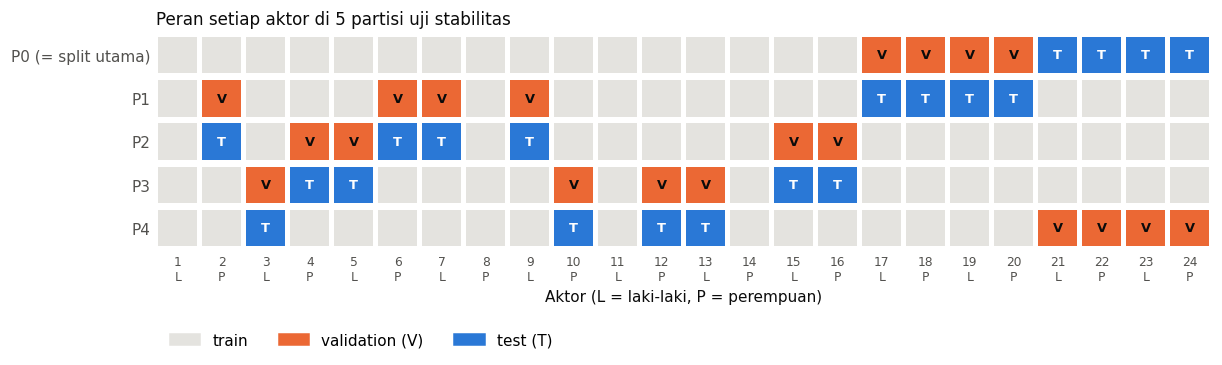

In [6]:
rows = []
for p, v in P.items():
    rows.append({'partisi': p, 'test': ', '.join(map(str, v['test'])),
                 'validation': ', '.join(map(str, v['validation'])),
                 'n aktor train': len(v['train']),
                 'file train': jumlah(v)['train'], 'file val': jumlah(v)['validation'], 'file test': jumlah(v)['test']})
tabel_part = pd.DataFrame(rows).set_index('partisi')
display(tabel_part)

def jac(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b)
J = pd.DataFrame([[jac(P[a]['train'], P[b]['train']) for b in P] for a in P], index=list(P), columns=list(P)).round(2)
print('Jaccard aktor train antarpartisi:')
display(J)
off = J.values[~np.eye(len(J), dtype=bool)]
print(f'Rata-rata Jaccard train antarpartisi (di luar diagonal): {off.mean():.2f} (rentang {off.min():.2f}-{off.max():.2f})')

# Grafik peran aktor per partisi
WARNA = {'train': '#e4e3df', 'validation': '#eb6834', 'test': '#2a78d6'}
HURUF = {'train': '', 'validation': 'V', 'test': 'T'}
fig, ax = plt.subplots(figsize=(11, 3.2), layout='constrained')
for i, (p, v) in enumerate(P.items()):
    for a in ACTORS:
        peran = 'test' if a in v['test'] else 'validation' if a in v['validation'] else 'train'
        ax.add_patch(plt.Rectangle((a - 0.5 + 0.06, i - 0.5 + 0.08), 0.88, 0.84, color=WARNA[peran], lw=0))
        if HURUF[peran]:
            ax.text(a, i, HURUF[peran], ha='center', va='center', fontsize=8.5, fontweight='bold',
                    color='white' if peran == 'test' else '#0b0b0b')
ax.set_xlim(0.5, len(ACTORS) + 0.5)
ax.set_ylim(len(P) - 0.5, -0.5)
ax.set_xticks(ACTORS)
ax.set_xticklabels([f"{a}\n{'L' if GENDER[a] == 'male' else 'P'}" for a in ACTORS], fontsize=8)
ax.set_yticks(range(len(P)))
ax.set_yticklabels([f'{p} (= split utama)' if p == 'P0' else p for p in P])
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xlabel('Aktor (L = laki-laki, P = perempuan)')
ax.set_title('Peran setiap aktor di 5 partisi uji stabilitas', loc='left', fontsize=11)
ax.legend(handles=[Patch(color=WARNA['train'], label='train'),
                   Patch(color=WARNA['validation'], label='validation (V)'),
                   Patch(color=WARNA['test'], label='test (T)')],
          loc='upper left', bbox_to_anchor=(0, -0.32), ncol=3, frameon=False)
fig.savefig(os.path.join(FIG_DIR, 'split_01_partisi_aktor.png'))
plt.show()

## Sel 6 — Pemeriksaan file tanpa frame bersuara

Di langkah 5 ada file dengan `voiced_ratio = 0`, artinya pyin tidak menemukan satu pun frame bernada, sehingga statistik F0 diisi 0. Sel ini memeriksa:

1. **Siapa file-file itu:** aktor, emosi, intensitas, durasi, kekerasan suara, dan masuk split mana.
2. **Apakah nadanya benar-benar tidak ada, atau pyin saja yang terlalu ketat?** pyin dijalankan ulang dengan pengaturan longgar (rentang 50–800 Hz, frame lebih panjang). Jika versi longgar menemukan frame bernada, berarti suaranya ada tetapi lemah, serak, atau berbisik.
3. **Pemutar audio** untuk didengar langsung.

Keputusan yang direncanakan: **file tetap dipakai** dan tabel fitur **tidak diubah** (nilai 0 sudah ditandai oleh `voiced_ratio = 0`). Mengubah tabel fitur berarti mengganti config_hash dan mengulang baseline B. Pemeriksaan ini untuk dokumentasi dan bahan keterbatasan di paper.

In [7]:
FC = CONFIG['features']
unv = fn[fn['voiced_ratio'] == 0][['file', 'actor', 'gender', 'emotion', 'intensity']].copy()
unv = unv.merge(plog[['file', 'proc_duration_s', 'rms_trim_db', 'peak_trim']], on='file', how='left')
unv['split_utama'] = unv['actor'].map(lambda a: next(k for k in ds.SPLIT_NAMES if a in S[k]))
print(f'File tanpa frame bersuara: {len(unv)} dari {len(fn)} ({len(unv) / len(fn):.2%})')

# Posisi dibanding file lain: voiced_ratio terendah setelah nol
lain = fn.loc[fn['voiced_ratio'] > 0, 'voiced_ratio']
print(f'voiced_ratio terendah di file lain: {lain.min():.3f} | persentil 1: {lain.quantile(0.01):.3f}')

def unit_peak(y):
    m = float(np.max(np.abs(y))) if len(y) else 0.0
    return (y / m).astype(np.float32) if m > 0 else y

hasil, sinyal = [], {}
for _, r in unv.iterrows():
    path = os.path.join(PROC_DIR, r['file'])
    if not os.path.exists(path):
        print('[CEK] file audio tidak ditemukan:', path)
        continue
    y, sr = sf.read(path, dtype='float32')
    yu = unit_peak(y)
    # pengaturan langkah 5
    _, vf0, vp0 = librosa.pyin(yu, fmin=FC['f0_fmin'], fmax=FC['f0_fmax'], sr=sr,
                               frame_length=FC['f0_frame_length'], hop_length=FC['hop_length'])
    # pengaturan longgar
    f1, vf1, vp1 = librosa.pyin(yu, fmin=50.0, fmax=800.0, sr=sr, frame_length=2048, hop_length=FC['hop_length'])
    ok = vf1 & np.isfinite(f1)
    sinyal[r['file']] = (y, sr, ok)
    hasil.append({'file': r['file'],
                  'max_voiced_prob_default': round(float(np.nanmax(vp0)), 3) if len(vp0) else 0.0,
                  'voiced_frames_longgar': int(ok.sum()),
                  'voiced_ratio_longgar': round(float(ok.mean()), 3),
                  'f0_median_longgar': round(float(np.median(f1[ok])), 1) if ok.any() else 0.0})

uc = unv.merge(pd.DataFrame(hasil), on='file', how='left')
uc['catatan_dengar'] = ''   # diisi manual setelah mendengar (opsional)
uc.to_csv(os.path.join(DATA_DIR, 'unvoiced_check.csv'), index=False)
pd.set_option('display.width', 200)
display(uc.drop(columns=['catatan_dengar']))

n_ada = int((uc['voiced_frames_longgar'] > 0).sum())
print(f'\nDengan pyin longgar: {n_ada} dari {len(uc)} file punya frame bernada; {len(uc) - n_ada} tetap tanpa nada.')
print('Distribusi emosi:', uc['emotion'].value_counts().to_dict())
print('Distribusi split utama:', uc['split_utama'].value_counts().to_dict())
print('Tersimpan:', os.path.join(DATA_DIR, 'unvoiced_check.csv'))

File tanpa frame bersuara: 5 dari 1440 (0.35%)
voiced_ratio terendah di file lain: 0.037 | persentil 1: 0.230


,file,actor,gender,emotion,intensity,proc_duration_s,rms_trim_db,peak_trim,split_utama,max_voiced_prob_default,voiced_frames_longgar,voiced_ratio_longgar,f0_median_longgar
0,Actor_03/03-01-07-02-01-01-03.wav,3,male,disgust,strong,2.496,-40.215179,0.108277,train,0.372,126,0.504,145.6
1,Actor_09/03-01-04-02-01-02-09.wav,9,male,sad,strong,2.720,-53.941992,0.018413,train,0.109,14,0.051,55.8
2,Actor_09/03-01-05-02-01-02-09.wav,9,male,angry,strong,1.888,-19.457042,0.690271,train,0.280,15,0.079,746.4
3,Actor_21/03-01-07-02-01-01-21.wav,21,male,disgust,strong,2.176,-36.786673,0.188898,test,0.048,12,0.055,735.7
4,Actor_21/03-01-08-02-02-01-21.wav,21,male,surprised,strong,1.536,-29.465027,0.266689,test,0.485,0,0.000,0.0



Dengan pyin longgar: 4 dari 5 file punya frame bernada; 1 tetap tanpa nada.
Distribusi emosi: {'disgust': 2, 'sad': 1, 'angry': 1, 'surprised': 1}
Distribusi split utama: {'train': 3, 'test': 2}
Tersimpan: /content/drive/MyDrive/project07/data/unvoiced_check.csv


**Cara membaca tabel:**
- `max_voiced_prob_default`: peluang bernada tertinggi menurut pyin dengan pengaturan langkah 5. Nilai mendekati 0 berarti memang hampir tidak ada nada.
- `voiced_frames_longgar` > 0: dengan pengaturan longgar ada nada yang terdeteksi. Biasanya suara sangat pelan, serak (*creaky*), atau berbisik.
- Pengaturan longgar juga bisa keliru menganggap desis atau noise sebagai nada, terutama jika frame bernadanya sedikit (misalnya di bawah 20) dan `f0_median_longgar` aneh (sangat rendah atau sangat tinggi). Karena itu, **hasil dengar yang menentukan**.
- `rms_trim_db` sangat rendah (misalnya di bawah −40 dB): rekaman sangat pelan.

Grafik di bawah menampilkan bentuk gelombang setiap file. Daerah oranye adalah frame yang dianggap bernada oleh pyin longgar.

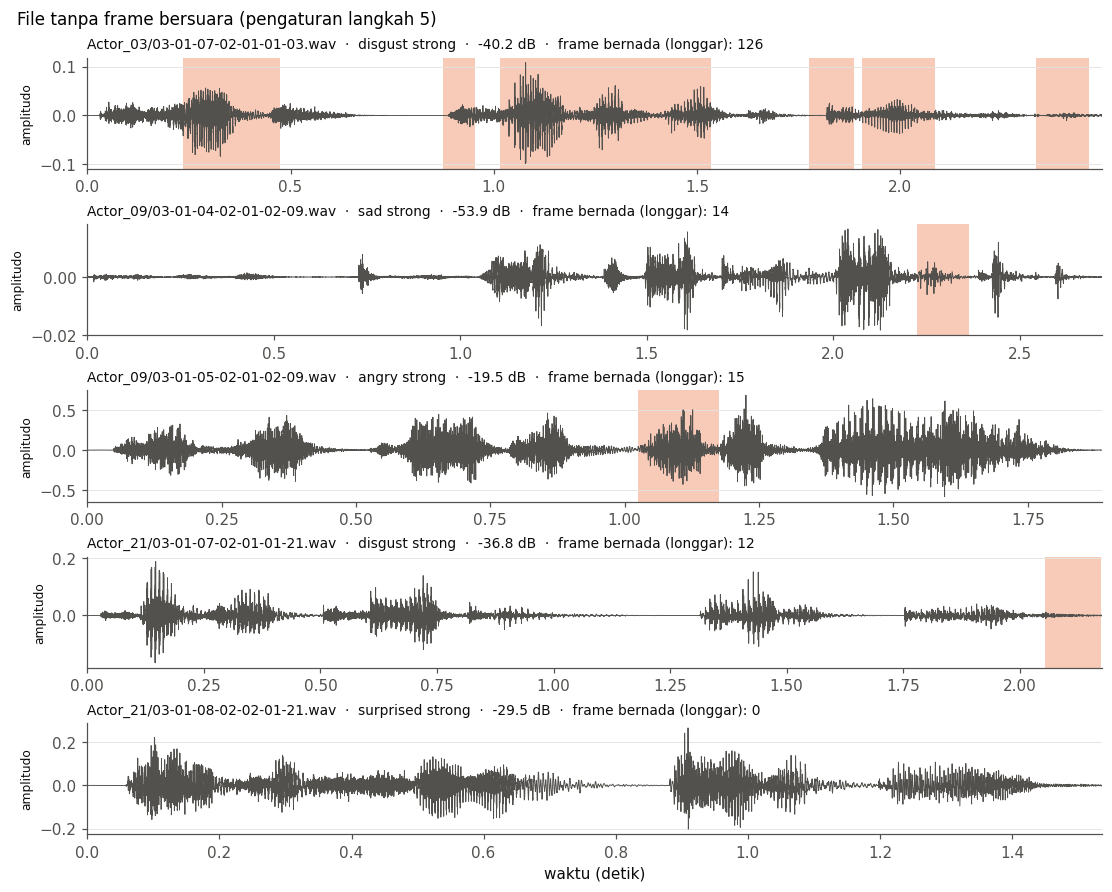

Dengarkan setiap file:
Actor_03/03-01-07-02-01-01-03.wav


Actor_09/03-01-04-02-01-02-09.wav


Actor_09/03-01-05-02-01-02-09.wav


Actor_21/03-01-07-02-01-01-21.wav


Actor_21/03-01-08-02-02-01-21.wav


In [8]:
if sinyal:
    fig, axes = plt.subplots(len(sinyal), 1, figsize=(10, 1.6 * len(sinyal)), layout='constrained', squeeze=False)
    hop = FC['hop_length']
    for ax, (f, (y, sr, ok)) in zip(axes[:, 0], sinyal.items()):
        t = np.arange(len(y)) / sr
        ax.plot(t, y, color='#52514e', lw=0.6)
        tf = np.arange(len(ok)) * hop / sr
        for i in np.flatnonzero(ok):
            ax.axvspan(tf[i] - hop / sr / 2, tf[i] + hop / sr / 2, color='#eb6834', alpha=0.35, lw=0)
        r = uc.set_index('file').loc[f]
        ax.set_title(f"{f}  ·  {r['emotion']} {r['intensity']}  ·  {r['rms_trim_db']:.1f} dB  ·  "
                     f"frame bernada (longgar): {r['voiced_frames_longgar']}", loc='left', fontsize=9)
        ax.set_ylabel('amplitudo', fontsize=8)
        ax.grid(axis='y', color='#e4e3df', lw=0.6)
        ax.set_xlim(0, max(t[-1], 0.1))
    axes[-1, 0].set_xlabel('waktu (detik)')
    fig.suptitle('File tanpa frame bersuara (pengaturan langkah 5)', x=0.01, ha='left', fontsize=11)
    fig.savefig(os.path.join(FIG_DIR, 'split_02_file_tanpa_nada.png'))
    plt.show()

    print('Dengarkan setiap file:')
    for f, (y, sr, ok) in sinyal.items():
        print(f)
        display(Audio(y, rate=sr))

**Yang perlu dicatat setelah mendengar** (kirim ke saya untuk Log Kerja): untuk setiap file, satu kata atau frasa singkat, misalnya *berbisik*, *serak*, *sangat pelan*, *ucapan normal* (jika terdengar normal, berarti pyin yang keliru). Tidak perlu mengubah apa pun di tabel fitur.

## Sel 7 — Ringkasan dan dokumentasi standar

Sel ini menyimpan `figures/splits/splits_summary.txt` dan `docs/README_langkah7_split_partisi.md`.

In [9]:
tgl = datetime.now().strftime('%Y-%m-%d')
n_ok = sum(t.startswith('[OK') for t in laporan)
ringkas = [
    f'Ringkasan split dan partisi (langkah 7, {tgl})',
    f"config_hash splits: {SPLIT_HASH} | config_hash fitur: {CONFIG['features']['config_hash']}",
    '',
    'Split utama (speaker-independent):',
] + [f"  {k:<10}: aktor {S[k][0]}-{S[k][-1]} ({len(S[k])} aktor, {n_file[k]} file, {gnd[k]}L/{len(S[k]) - gnd[k]}P)" for k in ds.SPLIT_NAMES] + [
    '',
    f'Partisi uji stabilitas (seed {SEED}, siklik, P0 = split utama):',
] + [f"  {p}: test {v['test']} | validation {v['validation']}" for p, v in P.items()] + [
    f'  selalu train: {SELALU_TRAIN}',
    f'  Jaccard aktor train antarpartisi: rata-rata {off.mean():.2f} (rentang {off.min():.2f}-{off.max():.2f})',
    '',
    f'File tanpa frame bersuara: {len(uc)} -> ' + ', '.join(f"{r.file} ({r.emotion} {r.intensity}, {r.split_utama})" for r in uc.itertuples()),
    f'  dengan pyin longgar: {n_ada} file punya frame bernada',
    '',
    f'Verifikasi: {n_ok}/{len(laporan)} OK',
] + ['  ' + t for t in laporan]
teks = '\n'.join(ringkas)
print(teks)
with open(os.path.join(FIG_DIR, 'splits_summary.txt'), 'w', encoding='utf-8') as f:
    f.write(teks + '\n')

baris_part = '\n'.join(f"| {p} | {', '.join(map(str, v['test']))} | {', '.join(map(str, v['validation']))} | {len(v['train'])} |"
                       for p, v in P.items())
baris_unv = '\n'.join(f"| `{r.file}` | {r.emotion} {r.intensity} | {r.split_utama} | {r.rms_trim_db:.1f} | {r.voiced_frames_longgar} |"
                      for r in uc.itertuples())
readme = f'''# Langkah 7 — Split Data per Aktor dan Partisi Uji Stabilitas

Penanggung jawab: Anggota A · Versi: 1.0 · Dijalankan: {tgl} · config_hash: `{SPLIT_HASH}` (fitur `{CONFIG['features']['config_hash']}`)

## Tujuan

Membagi data per aktor (speaker-independent) untuk eksperimen utama, membuat 5 partisi speaker untuk uji stabilitas seleksi fitur, dan memeriksa file tanpa frame bersuara.

## Output

| File | Isi |
| --- | --- |
| `data/splits.json` | Split utama: daftar aktor train, validation, test + jumlah file |
| `data/partitions.json` | Kelompok G0–G4, aktor selalu-train, partisi P0–P4 |
| `src/data_splits.py` | `load_splits`, `load_partitions`, `split_frames`, `split_masks`, `check_split` |
| `config.json` -> `splits` | Seed, rancangan, versi, config_hash |
| `data/unvoiced_check.csv` | Pemeriksaan file dengan `voiced_ratio = 0` |
| `figures/splits/` | `split_01_partisi_aktor.png`, `split_02_file_tanpa_nada.png`, `splits_summary.txt` |

## Split utama

| Bagian | Aktor | File | Gender |
| --- | --- | --- | --- |
''' + '\n'.join(f"| {k} | {S[k][0]}–{S[k][-1]} | {n_file[k]} | {gnd[k]} L / {len(S[k]) - gnd[k]} P |" for k in ds.SPLIT_NAMES) + f'''

Aturan: **test hanya dipakai sekali oleh Anggota C** untuk evaluasi akhir. Tuning (GroupKFold per aktor) dan SA hanya memakai train dan validation.

## Partisi uji stabilitas

Rancangan siklik: kelompok G0 = aktor 21–24, G1 = 17–20, G2–G4 diundi dari aktor 1–16 dengan seed {SEED} (masing-masing 2 L + 2 P). Partisi Pk memakai test = Gk, validation = G(k+1 mod 5), train = 16 aktor sisanya. Aktor {', '.join(map(str, SELALU_TRAIN))} selalu berada di train.

| Partisi | Test | Validation | Aktor train |
| --- | --- | --- | --- |
{baris_part}

- P0 identik dengan split utama, sehingga run SA utama dapat dipakai sebagai salah satu partisi.
- Setiap aktor paling banyak sekali menjadi test dan sekali menjadi validation.
- Jaccard aktor train antarpartisi rata-rata {off.mean():.2f} ({off.min():.2f}–{off.max():.2f}). Kemiripan subset fitur antarpartisi perlu dibaca relatif terhadap angka ini.
- Partisi hanya dipakai untuk eksperimen stabilitas setelah hasil utama final, **bukan** untuk memilih model utama. Aktor 21–24 ikut menjadi train/validation di P1–P4, jadi hasil partisi tidak boleh dipakai untuk mengubah keputusan yang dievaluasi di test utama.

## Cara memakai

```python
import sys
sys.path.insert(0, '/content/drive/MyDrive/project07/src')
import data_splits as ds
import pandas as pd

BASE_DIR = '/content/drive/MyDrive/project07'
fn = pd.read_csv(BASE_DIR + '/data/features/features_none.csv')
tr, va, te = ds.split_frames(fn, ds.load_splits(BASE_DIR))          # split utama
parts = ds.load_partitions(BASE_DIR)
for p, split in parts.items():                                     # P0..P4
    tr_p, va_p, te_p = ds.split_frames(fn, split)
```

## File tanpa frame bersuara

| File | Emosi | Split utama | RMS (dB) | Frame bernada (pyin longgar) |
| --- | --- | --- | --- | --- |
{baris_unv}

Keputusan: file tetap dipakai dan tabel fitur tidak diubah; statistik F0 bernilai 0 dan ditandai oleh `voiced_ratio = 0`. Dicatat sebagai keterbatasan estimasi F0.

## Verifikasi

{n_ok}/{len(laporan)} pemeriksaan OK.

''' + '\n'.join(f'- {t}' for t in laporan) + f'''

## Riwayat versi

| Versi | Tanggal | Perubahan |
| --- | --- | --- |
| 1.0 | {tgl} | Versi pertama |
'''
readme_path = os.path.join(DOC_DIR, 'README_langkah7_split_partisi.md')
with open(readme_path, 'w', encoding='utf-8') as f:
    f.write(readme)
print('\nTersimpan:', os.path.join(FIG_DIR, 'splits_summary.txt'))
print('Tersimpan:', readme_path)

Ringkasan split dan partisi (langkah 7, 2026-11-21)
config_hash splits: 04ad9a2f5b | config_hash fitur: 0c3114fc78

Split utama (speaker-independent):
  train     : aktor 1-16 (16 aktor, 960 file, 8L/8P)
  validation: aktor 17-20 (4 aktor, 240 file, 2L/2P)
  test      : aktor 21-24 (4 aktor, 240 file, 2L/2P)

Partisi uji stabilitas (seed 42, siklik, P0 = split utama):
  P0: test [21, 22, 23, 24] | validation [17, 18, 19, 20]
  P1: test [17, 18, 19, 20] | validation [2, 6, 7, 9]
  P2: test [2, 6, 7, 9] | validation [4, 5, 15, 16]
  P3: test [4, 5, 15, 16] | validation [3, 10, 12, 13]
  P4: test [3, 10, 12, 13] | validation [21, 22, 23, 24]
  selalu train: [1, 8, 11, 14]
  Jaccard aktor train antarpartisi: rata-rata 0.46 (rentang 0.33-0.60)

File tanpa frame bersuara: 5 -> Actor_03/03-01-07-02-01-01-03.wav (disgust strong, train), Actor_09/03-01-04-02-01-02-09.wav (sad strong, train), Actor_09/03-01-05-02-01-02-09.wav (angry strong, train), Actor_21/03-01-07-02-01-01-21.wav (disgust stro

## Selesai — yang dilakukan setelah notebook ini

1. Pastikan semua verifikasi di Sel 4 bertanda **OK**.
2. Simpan notebook ke `project07/notebooks/Langkah7_AnggotaA_Split_Partisi.ipynb`.
3. Dengarkan file di Sel 6 dan catat kesan singkat per file.
4. Kirim untuk dicatat di Log Kerja: isi `splits_summary.txt`, screenshot grafik `split_01` dan `split_02`, tabel Sel 6, dan catatan dengar.
5. Beri tahu **Anggota B**: `splits.json` dan `src/data_splits.py` siap; baseline final memakai split ini. `partitions.json` dipakai nanti untuk 15 run stabilitas.
6. Beri tahu **Anggota C**: `splits.json` (test aktor 21–24, hanya sekali) dan `partitions.json` untuk analisis stabilitas.